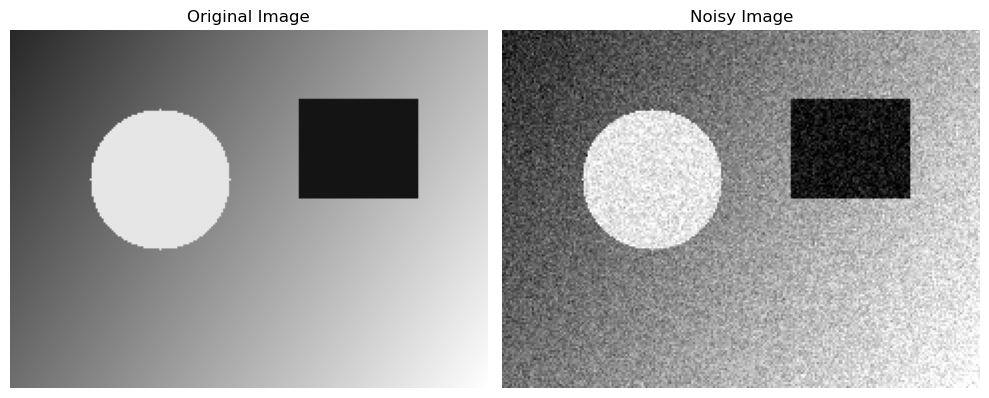

Enter filter size (odd number):  5
Enter padding method (zero/replication/reflection):  replication
Enter Gaussian sigma:  1.5


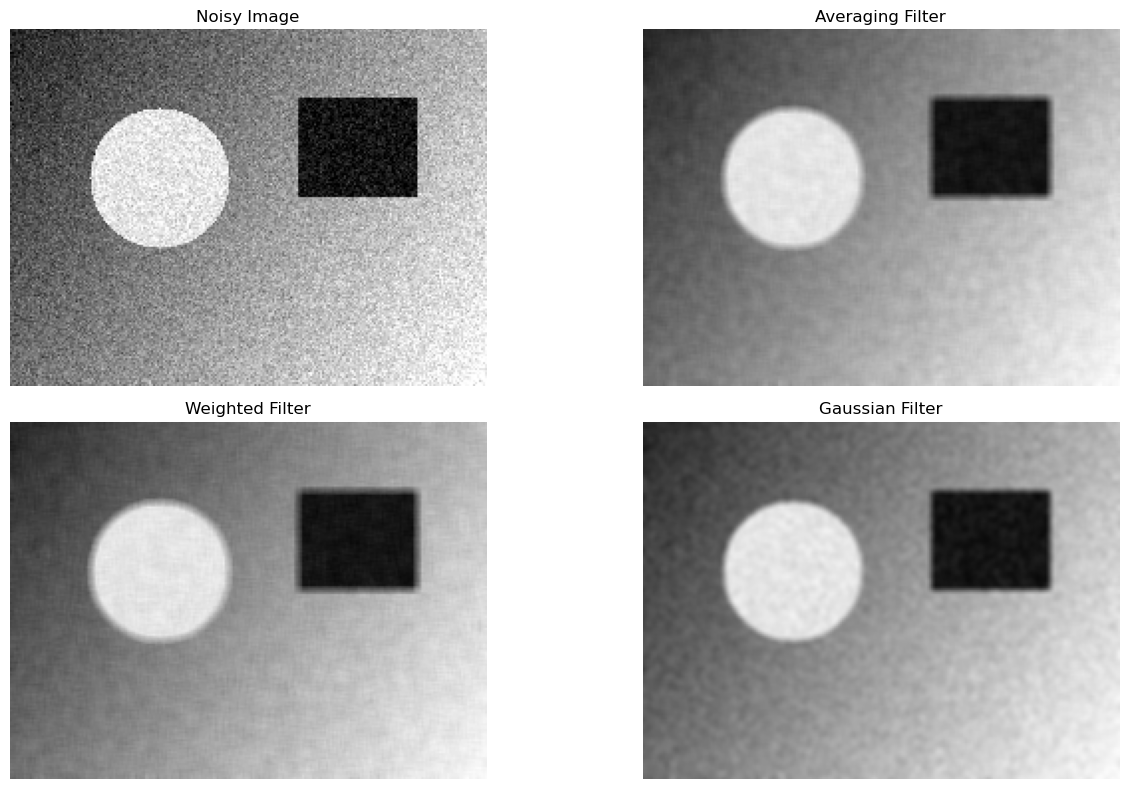

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate sample grayscale image
height, width = 180, 240
y, x = np.mgrid[0:height, 0:width]

gray_image = np.clip(40 + 0.6*x + 0.4*y, 0, 255).astype(np.uint8)

yy, xx = np.ogrid[:height, :width]
gray_image[(xx-75)**2 + (yy-75)**2 <= 35**2] = 230
gray_image[35:85, 145:205] = 20

# Add noise to the image
np.random.seed(42)
noise = np.random.normal(0, 20, gray_image.shape)
noisy_image = np.clip(
    gray_image.astype(float) + noise, 0, 255
).astype(np.uint8)

# Display original and noisy images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(noisy_image, cmap='gray', vmin=0, vmax=255)
plt.title("Noisy Image")
plt.axis('off')

plt.tight_layout()
plt.show()


# User parameters
filter_size = int(input("Enter filter size (odd number): "))
padding_method = input(
    "Enter padding method (zero/replication/reflection): "
).lower()
sigma = float(input("Enter Gaussian sigma: "))

if filter_size < 1 or filter_size % 2 == 0:
    raise ValueError("Filter size must be a positive odd number.")

if sigma <= 0:
    raise ValueError("Sigma must be positive.")

if padding_method not in ["zero", "replication", "reflection"]:
    raise ValueError("Invalid padding method.")


# Padding function
def apply_padding(image, size, method):
    pad = size // 2

    if method == "zero":
        return np.pad(image, pad, mode='constant')

    elif method == "replication":
        return np.pad(image, pad, mode='edge')

    else:
        return np.pad(image, pad, mode='reflect')


# Filtering function
def apply_filter(image, kernel, method):
    size = kernel.shape[0]
    padded = apply_padding(image, size, method)

    output = np.zeros(image.shape, dtype=float)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i+size, j:j+size]
            output[i, j] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)


# CASE 1: Averaging Filter
average_kernel = np.ones(
    (filter_size, filter_size)
) / (filter_size * filter_size)

average_output = apply_filter(
    noisy_image, average_kernel, padding_method
)


# CASE 2: Weighted Filter h(x,y)=max(|x|,|y|)
center = filter_size // 2

weighted_kernel = np.zeros(
    (filter_size, filter_size), dtype=float
)

for i in range(filter_size):
    for j in range(filter_size):
        weighted_kernel[i, j] = max(
            abs(i-center), abs(j-center)
        )

if weighted_kernel.sum() == 0:
    raise ValueError("Weighted filter requires size >= 3.")

weighted_kernel /= weighted_kernel.sum()

weighted_output = apply_filter(
    noisy_image, weighted_kernel, padding_method
)


# CASE 3: Gaussian Filter
ax = np.arange(-center, center+1)

gaussian_1d = np.exp(
    -(ax**2) / (2*sigma**2)
)

gaussian_1d /= gaussian_1d.sum()

gaussian_kernel = np.outer(
    gaussian_1d, gaussian_1d
)

gaussian_kernel /= gaussian_kernel.sum()

gaussian_output = apply_filter(
    noisy_image, gaussian_kernel, padding_method
)


# Display all outputs
images = [
    noisy_image,
    average_output,
    weighted_output,
    gaussian_output
]

titles = [
    "Noisy Image",
    "Averaging Filter",
    "Weighted Filter",
    "Gaussian Filter"
]

plt.figure(figsize=(14, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()